<a href="https://colab.research.google.com/github/whoiswasd/mineria/blob/main/Actividad-2.10/Actividad_2_10_Lopez_Pohla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 2.10 – Laboratorio de Clustering

**Asignatura:** Minería de Datos  
**Unidad:** II  
**Tema:** K-means y clustering jerárquico



# Ejercicio 1: Segmentación de clientes mediante K-means

**Objetivo:** Aplicar el algoritmo K-means para identificar grupos de clientes con características similares, utilizando sus ingresos anuales y su puntaje de gasto.

El propósito es analizar si existen diferentes tipos de clientes y proponer acciones de comunicación para cada segmento.

**Importar las librerías**

In [1]:

import os
from pathlib import Path

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

print("Librerías importadas correctamente")


Librerías importadas correctamente


**Descargar el dataset de Kaggle**

In [3]:

from google.colab import userdata

# Obtener el token desde los Secretos de Colab
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

# Descargar el dataset
carpeta = Path(
    kagglehub.dataset_download(
        "vjchoudhary7/customer-segmentation-tutorial-in-python"
    )
)

# Mostrar los archivos descargados
print("Archivos disponibles:")

for archivo in carpeta.rglob("*"):
    if archivo.is_file():
        print(archivo.name)


Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
Archivos disponibles:
Mall_Customers.csv


**Cargar y explorar los datos**

In [4]:

# Buscar el archivo CSV
archivo_csv = next(carpeta.rglob("Mall_Customers.csv"))

# Cargar los datos
df = pd.read_csv(archivo_csv)

# Mostrar las primeras filas
display(df.head())

# Dimensiones
print("Dimensiones:", df.shape)

# Tipos de datos
df.info()

# Valores nulos
print("\nValores nulos:")
print(df.isna().sum())

# Estadísticas descriptivas
display(df.describe())


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dimensiones: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Valores nulos:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


**Primera visualización e hipótesis**

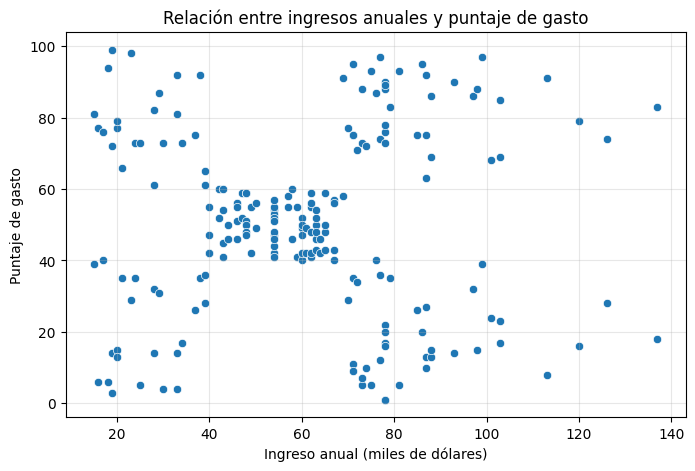

In [5]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)"
)

plt.title("Relación entre ingresos anuales y puntaje de gasto")
plt.xlabel("Ingreso anual (miles de dólares)")
plt.ylabel("Puntaje de gasto")
plt.grid(alpha=0.3)
plt.show()


**Hipótesis inicial**

Al observar el gráfico, considero que podrían existir aproximadamente 5 grupos de clientes. Se puede ver un grupo concentrado en el centro y otros grupos con diferentes combinaciones de ingresos y puntajes de gasto.

Mi hipótesis es que K-means podría identificar estos 5 segmentos, aunque será necesario comprobarlo con la inercia, la silueta y la estabilidad de los resultados.

**Selección de variables**

Para realizar el agrupamiento utilizaré el ingreso anual y el puntaje de gasto, ya que permiten comparar a los clientes según sus características de consumo.

No utilizaré CustomerID porque solamente identifica a cada cliente. Tampoco incluiré Gender, porque es una variable categórica y convertirla en números podría afectar las distancias calculadas por el algoritmo.

Por ahora dejaré fuera Age para trabajar con dos variables y visualizar mejor los grupos.


**Preparar y estandarizar los datos**

In [6]:

# Seleccionar las variables
columnas = ["Annual Income (k$)", "Spending Score (1-100)"]

X = df[columnas].copy()

# Mostrar los rangos originales
print("Rangos originales:")
display(X.agg(["min", "max"]))

# Estandarizar los datos
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X)

# Guardar como DataFrame
X_escalado = pd.DataFrame(
    X_escalado,
    columns=columnas,
    index=X.index
)

print("\nDatos estandarizados:")
display(X_escalado.head())

print("\nMedia después de estandarizar:")
print(X_escalado.mean().round(4))

print("\nDesviación estándar poblacional:")
print(X_escalado.std(ddof=0).round(4))


Rangos originales:


,Annual Income (k$),Spending Score (1-100)
min,15,1
max,137,99



Datos estandarizados:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Media después de estandarizar:
Annual Income (k$)       -0.0
Spending Score (1-100)   -0.0
dtype: float64

Desviación estándar poblacional:
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64


**Estandarización de los datos**

El ingreso anual tiene valores entre 15 y 137, mientras que el puntaje de gasto va desde 1 hasta 99.

Decidí estandarizar ambas variables para que tengan una escala comparable al calcular las distancias entre clientes. De esta manera, el algoritmo no dará mayor importancia a una variable solamente porque sus valores numéricos sean más grandes.

**Ejecutar K-means con diferentes valores de k**

In [7]:

# Valores de k que vamos a probar
valores_k = range(2, 11)

inercias = []
siluetas = []

for k in valores_k:

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_escalado)

    inercias.append(modelo.inertia_)

    siluetas.append(
        silhouette_score(X_escalado, etiquetas)
    )

# Tabla de resultados
resultados_k = pd.DataFrame({
    "k": list(valores_k),
    "Inercia": inercias,
    "Silueta": siluetas
})

display(resultados_k.round(4))


,k,Inercia,Silueta
0,2,269.6910,0.3213
1,3,157.7040,0.4666
2,4,108.9213,0.4939
3,5,65.5684,0.5547
4,6,55.0573,0.5399
5,7,44.8648,0.5281
6,8,37.2282,0.4552
7,9,32.3923,0.4571
8,10,29.9819,0.4432


**Graficar inercia y silueta**

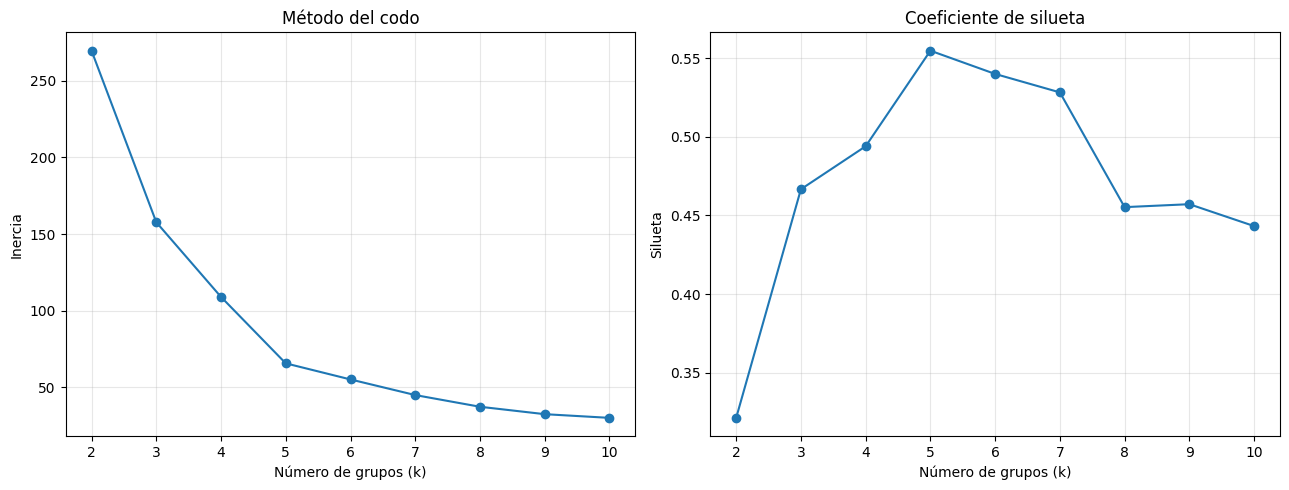

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Método del codo
axes[0].plot(
    resultados_k["k"],
    resultados_k["Inercia"],
    marker="o"
)

axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de grupos (k)")
axes[0].set_ylabel("Inercia")
axes[0].grid(alpha=0.3)

# Coeficiente de silueta
axes[1].plot(
    resultados_k["k"],
    resultados_k["Silueta"],
    marker="o"
)

axes[1].set_title("Coeficiente de silueta")
axes[1].set_xlabel("Número de grupos (k)")
axes[1].set_ylabel("Silueta")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Selección del número de grupos**

Después de comparar los resultados, considero que 5 es un buen número de grupos para este dataset.

En el método del codo se observa que la inercia disminuye bastante hasta k = 5 y después las mejoras son menores. Además, el coeficiente de silueta alcanza su valor más alto en k = 5, con aproximadamente 0.5547.

La inercia disminuye al aumentar la cantidad de grupos porque los clientes pueden quedar más cerca de sus centroides. Por eso, no es suficiente utilizar solamente este indicador para elegir k.

Estos resultados apoyan mi hipótesis inicial de que existen aproximadamente 5 segmentos de clientes. Todavía falta comprobar su estabilidad y si los grupos tienen utilidad para la tienda.

**Comprobar la estabilidad de K-means**

In [9]:

# Modelo de referencia
modelo_base = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

etiquetas_base = modelo_base.fit_predict(X_escalado)

# Probar diferentes semillas
semillas = [0, 10, 21, 50, 100]
resultados_estabilidad = []

for semilla in semillas:
    modelo = KMeans(
        n_clusters=5,
        random_state=semilla,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_escalado)

    ari = adjusted_rand_score(
        etiquetas_base,
        etiquetas
    )

    resultados_estabilidad.append({
        "Semilla": semilla,
        "ARI": ari
    })

display(pd.DataFrame(resultados_estabilidad))


,Semilla,ARI
0,0,1.0
1,10,1.0
2,21,1.0
3,50,1.0
4,100,1.0


**Comparar con y sin estandarización**

In [10]:

# K-means sin estandarización
modelo_original = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

etiquetas_original = modelo_original.fit_predict(X)

# Comparar ambas particiones
ari_escala = adjusted_rand_score(
    etiquetas_base,
    etiquetas_original
)

print("ARI entre ambas versiones:", round(ari_escala, 4))

# Tabla de comparación
comparacion = pd.crosstab(
    pd.Series(etiquetas_base, name="Estandarizado"),
    pd.Series(etiquetas_original, name="Sin estandarizar")
)

display(comparacion)


ARI entre ambas versiones: 1.0


Sin estandarizar,0,1,2,3,4
Estandarizado,,,,,
0,81,0,0,0,0
1,0,39,0,0,0
2,0,0,22,0,0
3,0,0,0,35,0
4,0,0,0,0,23


**Visualizar la comparación**

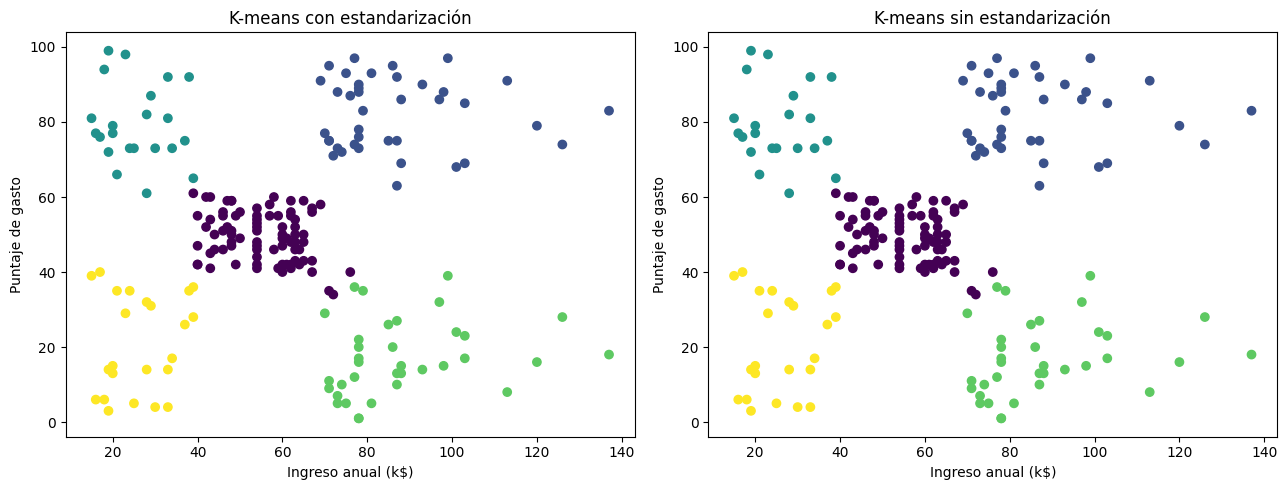

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=etiquetas_base,
    cmap="viridis"
)

axes[0].set_title("K-means con estandarización")
axes[0].set_xlabel("Ingreso anual (k$)")
axes[0].set_ylabel("Puntaje de gasto")

axes[1].scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=etiquetas_original,
    cmap="viridis"
)

axes[1].set_title("K-means sin estandarización")
axes[1].set_xlabel("Ingreso anual (k$)")
axes[1].set_ylabel("Puntaje de gasto")

plt.tight_layout()
plt.show()


**Crear los perfiles de clientes**

In [12]:

# Copiar dataset original
df_clusters = df.copy()

# Agregar grupos
df_clusters["Cluster"] = etiquetas_base

# Calcular perfiles
perfiles = df_clusters.groupby("Cluster").agg(
    Clientes=("CustomerID", "count"),
    Ingreso_promedio=("Annual Income (k$)", "mean"),
    Ingreso_mediana=("Annual Income (k$)", "median"),
    Gasto_promedio=("Spending Score (1-100)", "mean"),
    Gasto_mediana=("Spending Score (1-100)", "median"),
    Edad_promedio=("Age", "mean")
)

display(perfiles.round(2))


,Clientes,Ingreso_promedio,Ingreso_mediana,Gasto_promedio,Gasto_mediana,Edad_promedio
Cluster,,,,,,
0,81,55.30,54.0,49.52,50.0,42.72
1,39,86.54,79.0,82.13,83.0,32.69
2,22,25.73,24.5,79.36,77.0,25.27
3,35,88.20,85.0,17.11,16.0,41.11
4,23,26.30,25.0,20.91,17.0,45.22


**Visualizar los cinco segmentos y sus centroides**

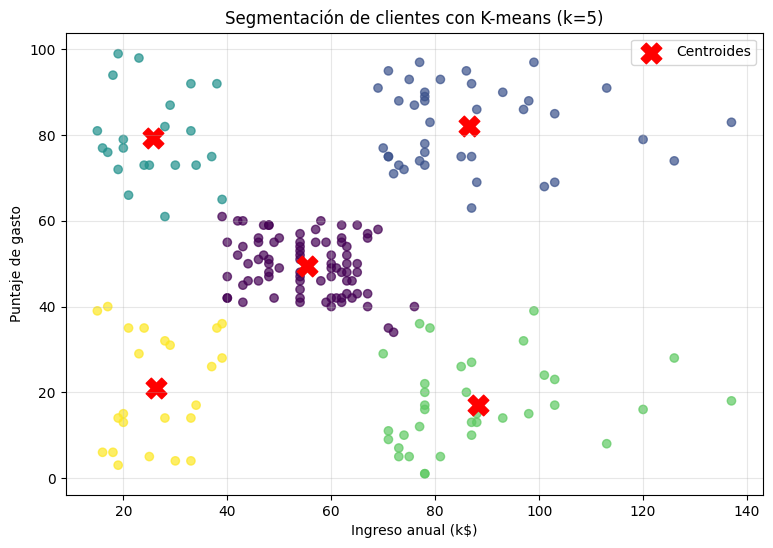

In [13]:

# Convertir centroides a unidades originales
centroides = scaler.inverse_transform(
    modelo_base.cluster_centers_
)

plt.figure(figsize=(9, 6))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=etiquetas_base,
    cmap="viridis",
    alpha=0.7
)

plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    c="red",
    marker="X",
    s=220,
    label="Centroides"
)

plt.title("Segmentación de clientes con K-means (k=5)")
plt.xlabel("Ingreso anual (k$)")
plt.ylabel("Puntaje de gasto")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Interpretación de los cinco segmentos**

El algoritmo K-means permitió identificar cinco grupos de clientes con diferentes niveles de ingreso y gasto.

El cluster 0 es el más grande, con 81 clientes que presentan ingresos y gastos medios. El cluster 1 contiene 39 clientes con ingresos y gastos altos. El cluster 2 agrupa a 22 clientes con ingresos bajos, pero puntajes de gasto altos.

Por otro lado, el cluster 3 tiene 35 clientes con ingresos altos y gastos bajos, mientras que el cluster 4 contiene 23 clientes con ingresos y gastos bajos.

Para cada segmento se podrían probar diferentes promociones y estrategias de comunicación, dependiendo de sus características.

**Conclusión del ejercicio 1**

Mi hipótesis inicial fue que existían aproximadamente cinco grupos y los resultados apoyaron esa idea. El valor más alto de silueta fue 0.5547 para k = 5 y el método del codo también mostró una disminución importante de la inercia hasta ese punto.

Al probar diferentes semillas, el ARI fue de 1.0, lo que indica que los grupos se mantuvieron estables en estas pruebas. También comparé los datos estandarizados y originales, obteniendo un ARI de 1.0, por lo que la escala no cambió los grupos en este caso.

Me llamó la atención que existieran clientes con ingresos altos y gastos bajos, y otros con ingresos bajos y gastos altos. Esto demuestra que tener mayores ingresos no necesariamente significa tener un puntaje de gasto más alto.

Considero que estos segmentos pueden ayudar a la tienda a probar promociones diferenciadas. Sin embargo, los grupos dependen de las variables utilizadas y no permiten conocer todas las características o preferencias de los clientes.

# Ejercicio 2. Clustering jerárquico: ¿con qué países se parece Chile?

Objetivo: Utilizar clustering jerárquico para identificar países que presentan características similares a Chile, considerando indicadores socioeconómicos y de salud.

Se utilizarán dendrogramas para analizar las agrupaciones y comparar diferentes métodos de enlace.

**Descargar el segundo dataset**

In [14]:

# Descargar dataset de países
carpeta_paises = Path(
    kagglehub.dataset_download(
        "rohan0301/unsupervised-learning-on-country-data"
    )
)

# Mostrar archivos disponibles
print("Archivos disponibles:")

for archivo in carpeta_paises.rglob("*"):
    if archivo.is_file():
        print(archivo.name)


100%|██████████| 5.21k/5.21k [00:00<00:00, 2.97MB/s]

Extracting files...
Archivos disponibles:
data-dictionary.csv
Country-data.csv


**Cargar y explorar los países**

In [15]:

# Buscar archivo principal
archivo_paises = next(
    carpeta_paises.rglob("Country-data.csv")
)

# Cargar dataset
df_paises = pd.read_csv(archivo_paises)

# Mostrar primeras filas
display(df_paises.head())

# Dimensiones
print("Dimensiones:", df_paises.shape)

# Información de columnas
df_paises.info()

# Valores nulos
print("\nValores nulos:")
print(df_paises.isna().sum())

# Estadísticas descriptivas
display(df_paises.describe())

# Verificar Chile
print("\nRegistros correspondientes a Chile:")
display(
    df_paises[
        df_paises["country"].str.lower() == "chile"
    ]
)


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


Dimensiones: (167, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB

Valores nulos:
country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000



Registros correspondientes a Chile:


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
33,Chile,8.7,37.7,7.96,31.3,19400,8.96,79.1,1.88,12900


**Revisar nombres de países**

In [16]:

# Mostrar nombres de países
print("Países disponibles:")

for pais in sorted(df_paises["country"].unique()):
    print(pais)


Países disponibles:
Afghanistan
Albania
Algeria
Angola
Antigua and Barbuda
Argentina
Armenia
Australia
Austria
Azerbaijan
Bahamas
Bahrain
Bangladesh
Barbados
Belarus
Belgium
Belize
Benin
Bhutan
Bolivia
Bosnia and Herzegovina
Botswana
Brazil
Brunei
Bulgaria
Burkina Faso
Burundi
Cambodia
Cameroon
Canada
Cape Verde
Central African Republic
Chad
Chile
China
Colombia
Comoros
Congo, Dem. Rep.
Congo, Rep.
Costa Rica
Cote d'Ivoire
Croatia
Cyprus
Czech Republic
Denmark
Dominican Republic
Ecuador
Egypt
El Salvador
Equatorial Guinea
Eritrea
Estonia
Fiji
Finland
France
Gabon
Gambia
Georgia
Germany
Ghana
Greece
Grenada
Guatemala
Guinea
Guinea-Bissau
Guyana
Haiti
Hungary
Iceland
India
Indonesia
Iran
Iraq
Ireland
Israel
Italy
Jamaica
Japan
Jordan
Kazakhstan
Kenya
Kiribati
Kuwait
Kyrgyz Republic
Lao
Latvia
Lebanon
Lesotho
Liberia
Libya
Lithuania
Luxembourg
Macedonia, FYR
Madagascar
Malawi
Malaysia
Maldives
Mali
Malta
Mauritania
Mauritius
Micronesia, Fed. Sts.
Moldova
Mongolia
Montenegro
Morocco
Mozamb

**Seleccionar un subconjunto de países**

In [17]:

# Separar Chile del resto de países
chile = df_paises[df_paises["country"] == "Chile"]

otros_paises = df_paises[
    df_paises["country"] != "Chile"
]

# Seleccionar 29 países aleatoriamente
muestra = otros_paises.sample(
    n=29,
    random_state=42
)

# Unir Chile con la muestra
df_muestra = pd.concat(
    [chile, muestra],
    ignore_index=True
)

# Ordenar alfabéticamente
df_muestra = df_muestra.sort_values(
    "country"
).reset_index(drop=True)

print("Cantidad de países:", len(df_muestra))

print("\nPaíses seleccionados:")
print(df_muestra["country"].to_string(index=False))


Cantidad de países: 30

Países seleccionados:
              Azerbaijan
              Bangladesh
                 Belgium
                  Belize
                  Bhutan
                 Bolivia
                Bulgaria
                  Canada
Central African Republic
                   Chile
          Czech Republic
                    Fiji
                  Gambia
                 Georgia
                 Grenada
                 Iceland
                 Jamaica
                   Japan
              Kazakhstan
         Kyrgyz Republic
                   Malta
   Micronesia, Fed. Sts.
                 Moldova
                 Morocco
                   Nepal
            Sierra Leone
               Singapore
         Solomon Islands
            South Africa
               Venezuela


Para este ejercicio seleccioné una muestra de 30 países, incluyendo a Chile. Utilicé una selección aleatoria con una semilla fija para que los resultados puedan reproducirse.

Elegí esta cantidad porque permite construir un dendrograma más fácil de interpretar que uno con los 167 países originales.

Mi hipótesis inicial es que Chile podría agruparse con países que tengan indicadores económicos y de salud similares, como Argentina o Uruguay. Sin embargo, esto dependerá de los países seleccionados y de las variables utilizadas.

**Analizar las variables y sus escalas**

In [18]:

# Seleccionar variables numéricas
variables = df_muestra.drop(columns=["country"])

# Mostrar rangos
rangos = variables.agg(["min", "max"])

display(rangos.T)

# Mostrar estadísticas descriptivas
display(variables.describe().T)


,min,max
child_mort,2.60,160.00
exports,9.58,200.00
health,3.52,14.20
imports,13.60,174.00
income,888.00,72100.00
inflation,-1.90,45.90
life_expec,47.50,82.80
total_fer,1.15,5.71
gdpp,399.00,47400.00


,count,mean,std,min,25%,50%,75%,max
child_mort,30.0,33.180000,37.964879,2.60,9.2250,20.150,42.0250,160.00
exports,30.0,46.666000,39.490247,9.58,24.9750,38.450,52.9500,200.00
health,30.0,7.282333,2.918733,3.52,4.9825,6.030,9.2850,14.20
imports,30.0,54.623333,36.103039,13.60,31.0750,46.250,69.0000,174.00
income,30.0,15461.600000,16570.640954,888.00,3482.5000,7940.000,19925.0000,72100.00
inflation,30.0,7.457000,9.053895,-1.90,1.9125,5.730,9.5975,45.90
life_expec,30.0,71.050000,8.560041,47.50,68.3250,71.500,76.9750,82.80
total_fer,30.0,2.571000,1.173593,1.15,1.8650,2.355,2.7000,5.71
gdpp,30.0,12017.900000,15912.911237,399.00,1717.5000,4510.000,13350.0000,47400.00


**Visualizar distribuciones y valores atípicos**

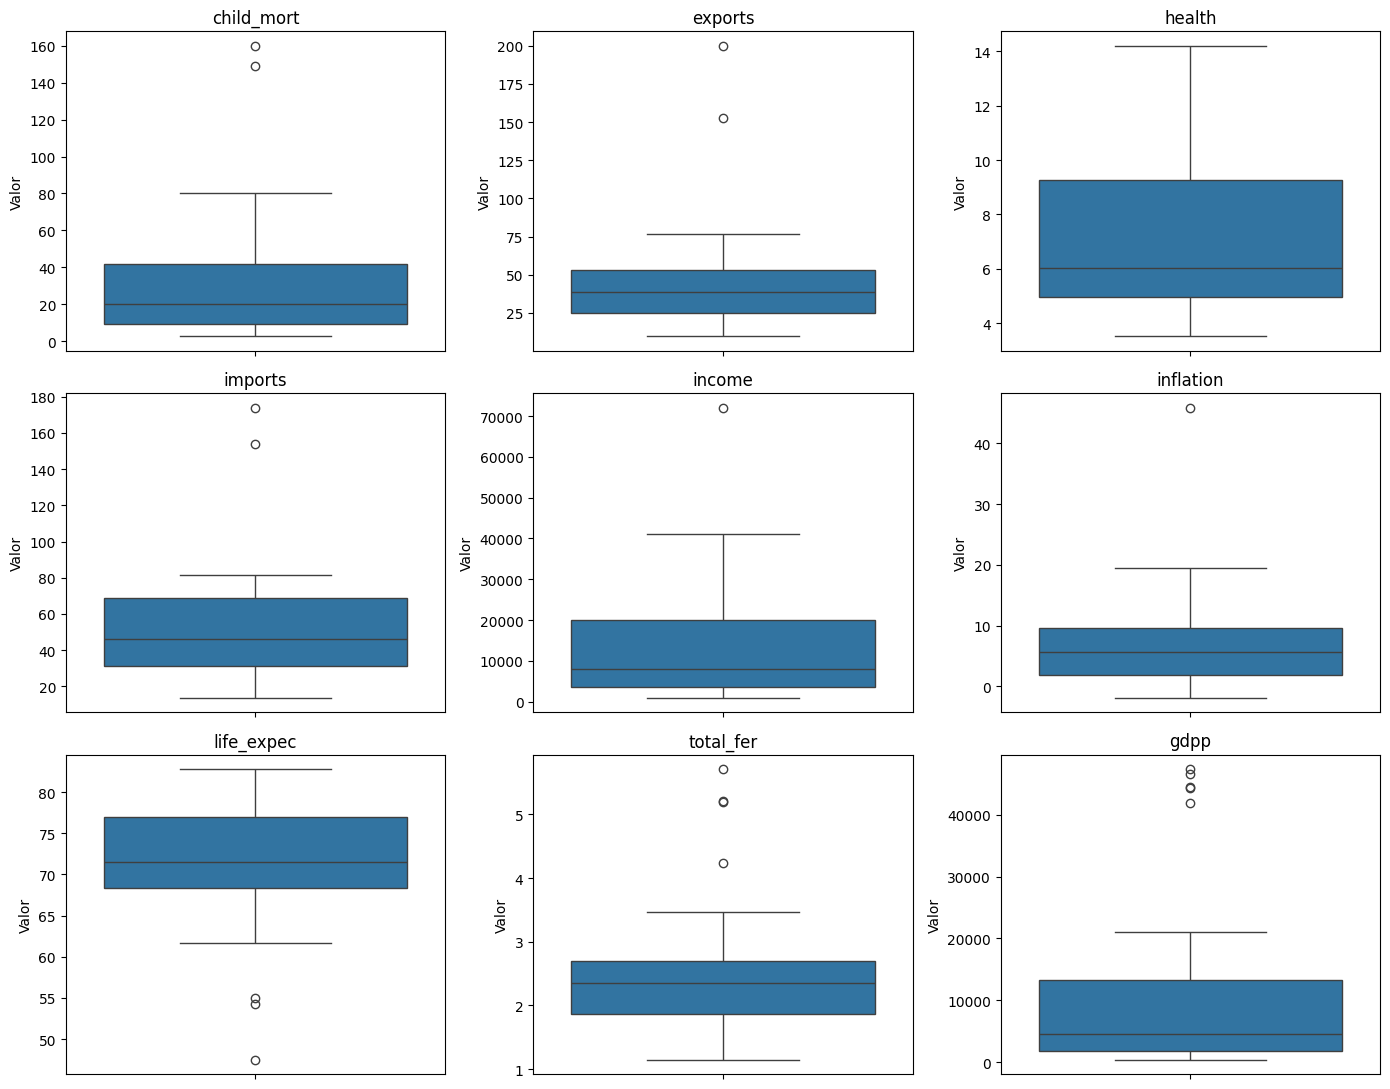

In [19]:

# Crear boxplots para cada variable
fig, axes = plt.subplots(3, 3, figsize=(14, 11))

for ax, columna in zip(axes.flatten(), variables.columns):
    sns.boxplot(
        y=variables[columna],
        ax=ax
    )
    ax.set_title(columna)
    ax.set_ylabel("Valor")

plt.tight_layout()
plt.show()


**Matriz de correlación**

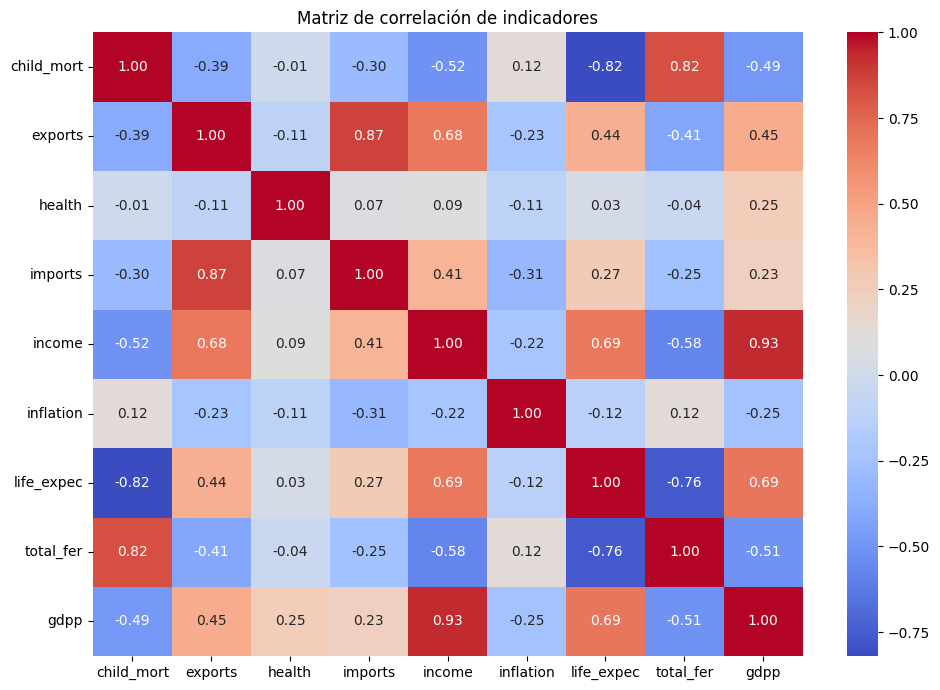

In [20]:

# Calcular correlaciones
correlacion = variables.corr()

# Crear mapa de calor
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación de indicadores")
plt.tight_layout()
plt.show()


**Preparar datos originales y estandarizados**

In [21]:

# Datos originales
X_paises_original = variables.copy()

# Estandarizar
scaler_paises = StandardScaler()

X_paises_escalado = pd.DataFrame(
    scaler_paises.fit_transform(X_paises_original),
    columns=X_paises_original.columns,
    index=X_paises_original.index
)

# Guardar nombres de países
nombres_paises = df_muestra["country"].tolist()

print("Datos originales:")
display(X_paises_original.head())

print("\nDatos estandarizados:")
display(X_paises_escalado.head())

print("\nMedias estandarizadas:")
print(X_paises_escalado.mean().round(4))

print("\nDesviaciones estándar poblacionales:")
print(X_paises_escalado.std(ddof=0).round(4))


Datos originales:


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,39.2,54.3,5.88,20.7,16000,13.80,69.1,1.92,5840
1,49.4,16.0,3.52,21.8,2440,7.14,70.4,2.33,758
2,4.5,76.4,10.70,74.7,41100,1.88,80.0,1.86,44400
3,18.8,58.2,5.20,57.5,7880,1.14,71.4,2.71,4340
4,42.7,42.5,5.20,70.7,6420,5.99,72.1,2.38,2180



Datos estandarizados:


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,0.161278,0.196618,-0.488673,-0.955689,0.033047,0.712559,-0.231697,-0.564190,-0.394869
1,0.434541,-0.789821,-1.311066,-0.924699,-0.799257,-0.035611,-0.077232,-0.208863,-0.719692
2,-0.768349,0.765817,1.190959,0.565600,1.573668,-0.626508,1.063430,-0.616189,2.069746
3,-0.385246,0.297065,-0.725634,0.081041,-0.465354,-0.709638,0.041587,0.120464,-0.490743
4,0.255045,-0.107298,-0.725634,0.452912,-0.554968,-0.164800,0.124760,-0.165530,-0.628803



Medias estandarizadas:
child_mort    0.0
exports       0.0
health        0.0
imports      -0.0
income       -0.0
inflation     0.0
life_expec    0.0
total_fer    -0.0
gdpp         -0.0
dtype: float64

Desviaciones estándar poblacionales:
child_mort    1.0
exports       1.0
health        1.0
imports       1.0
income        1.0
inflation     1.0
life_expec    1.0
total_fer     1.0
gdpp          1.0
dtype: float64


Las variables del dataset tienen magnitudes muy diferentes. Por ejemplo, los ingresos y el PIB por persona presentan valores mucho mayores que la esperanza de vida o la tasa de fertilidad.

Si utilizara los datos originales con distancia euclidiana, las variables con valores más grandes podrían dominar el cálculo de las distancias.

Por eso decidí estandarizar los datos, para que las variables tengan una escala comparable.

Mi predicción es que el dendrograma cambiará al utilizar los datos estandarizados, porque las distancias entre países ya no estarán dominadas solamente por las variables de mayor magnitud.

**Interpretación de la exploración**

Al revisar los datos observé que las variables tienen escalas bastante diferentes. Por ejemplo, income alcanza un valor de 72.100, mientras que total_fer llega solamente a 5.71 en la muestra.

En los boxplots también aparecen algunos valores atípicos, principalmente en ingresos, exportaciones, importaciones e inflación.

La matriz de correlación muestra una relación positiva fuerte entre income y gdpp (0.93), mientras que child_mort y life_expec tienen una relación negativa de -0.82.

Por estos motivos considero importante estandarizar las variables antes de aplicar clustering jerárquico, ya que las diferencias de escala podrían afectar las distancias entre países.

**Construir los cuatro dendrogramas**

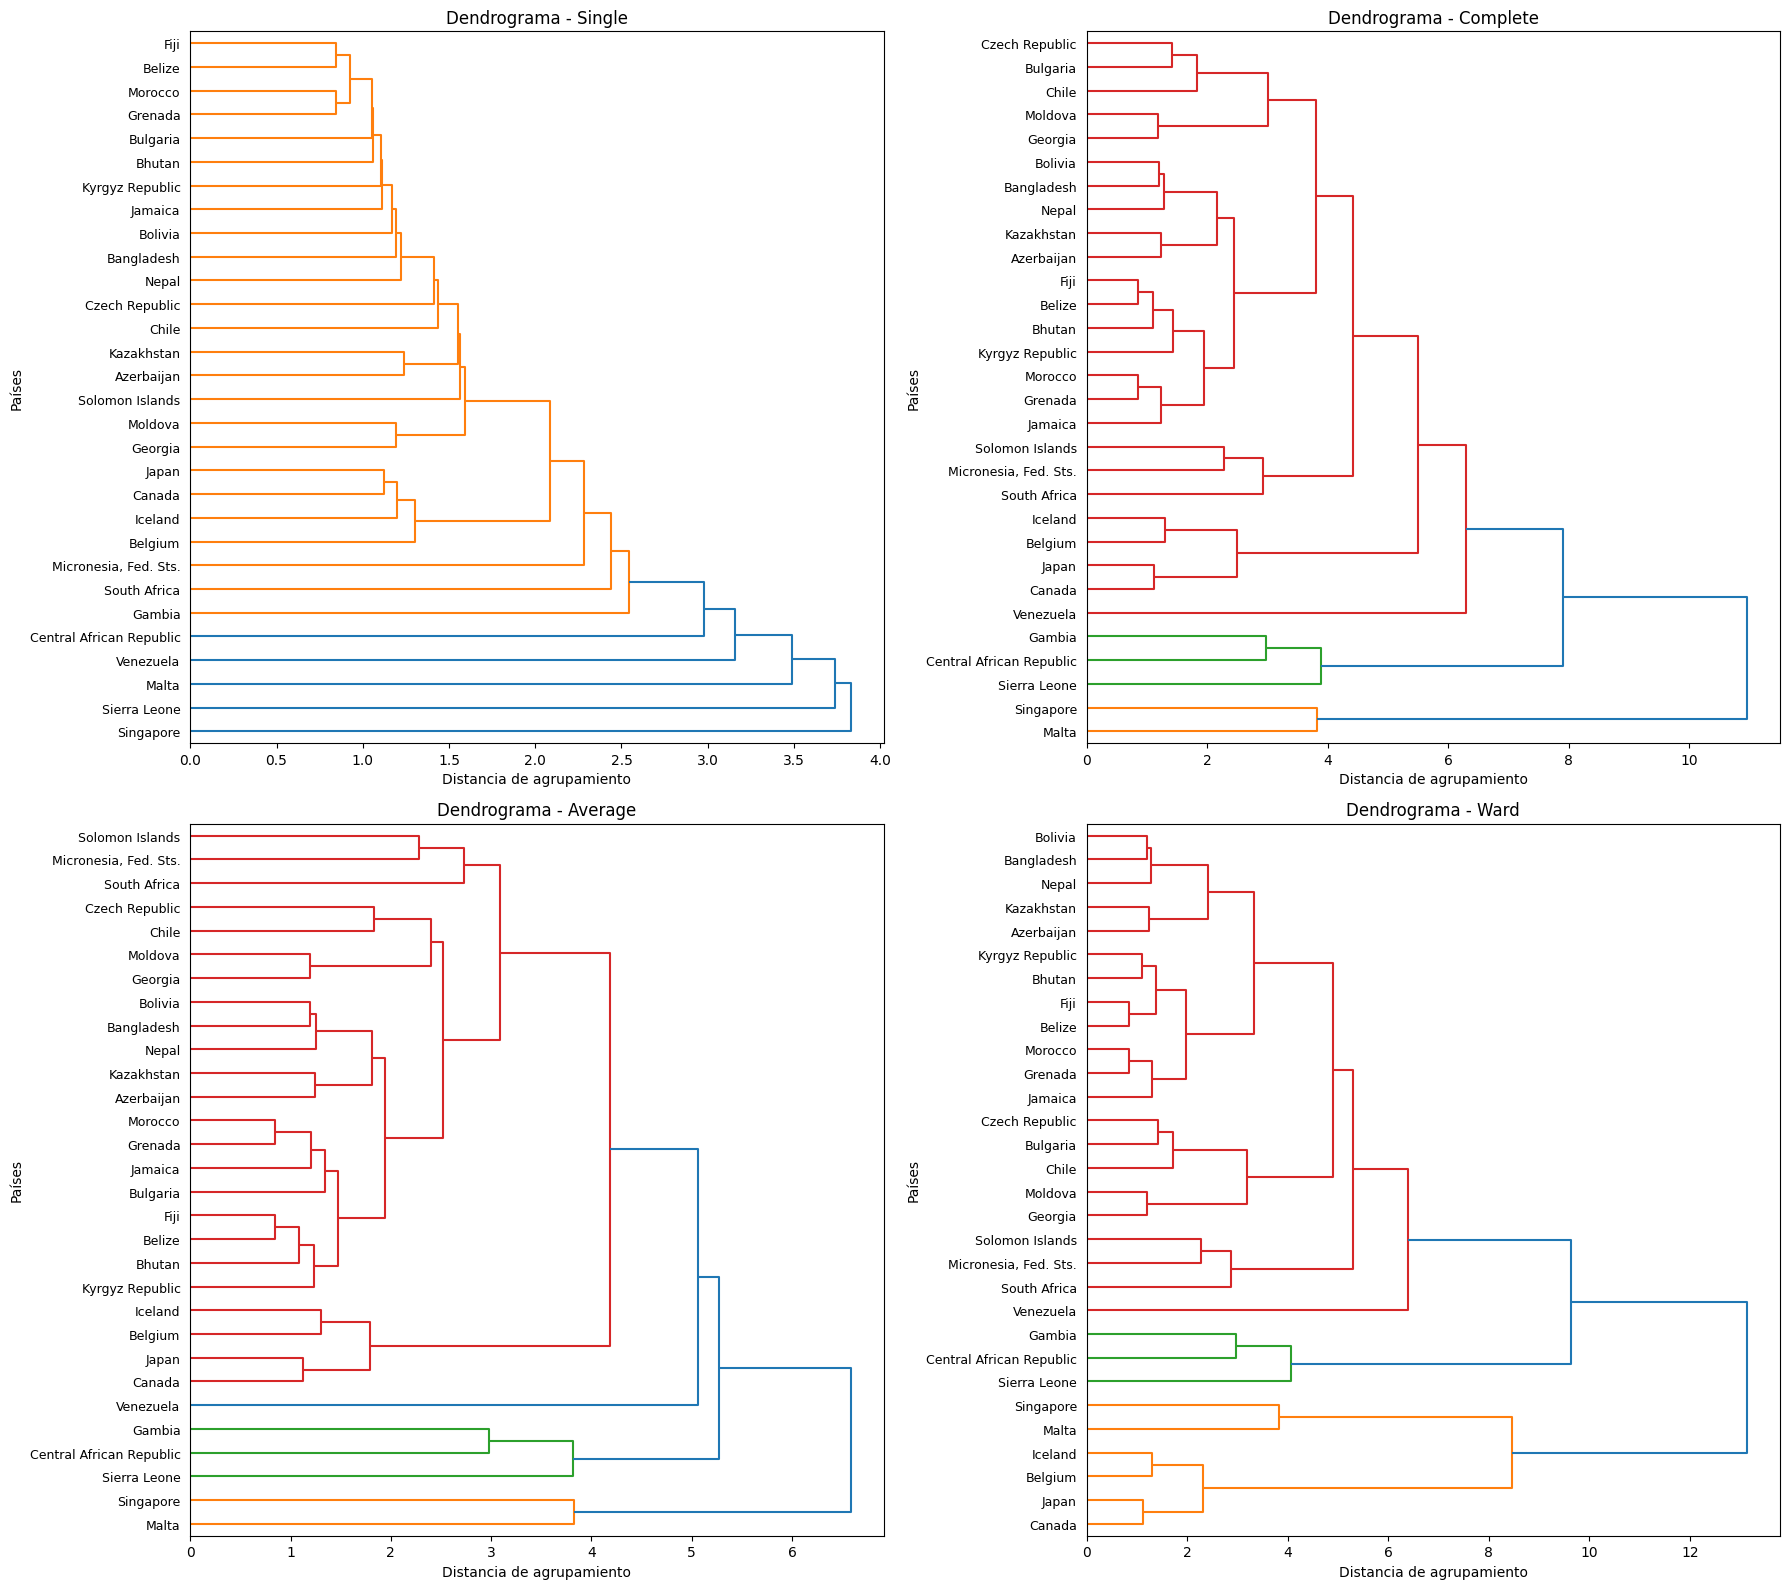

In [22]:

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Métodos de enlace
metodos = ["single", "complete", "average", "ward"]

# Crear figura
fig, axes = plt.subplots(2, 2, figsize=(18, 16))

# Generar dendrogramas
for ax, metodo in zip(axes.flatten(), metodos):

    Z = linkage(
        X_paises_escalado,
        method=metodo,
        metric="euclidean"
    )

    dendrogram(
        Z,
        labels=nombres_paises,
        orientation="right",
        leaf_font_size=9,
        ax=ax
    )

    ax.set_title(f"Dendrograma - {metodo.capitalize()}")
    ax.set_xlabel("Distancia de agrupamiento")
    ax.set_ylabel("Países")

plt.tight_layout()
plt.show()


**Comparar datos estandarizados y originales**

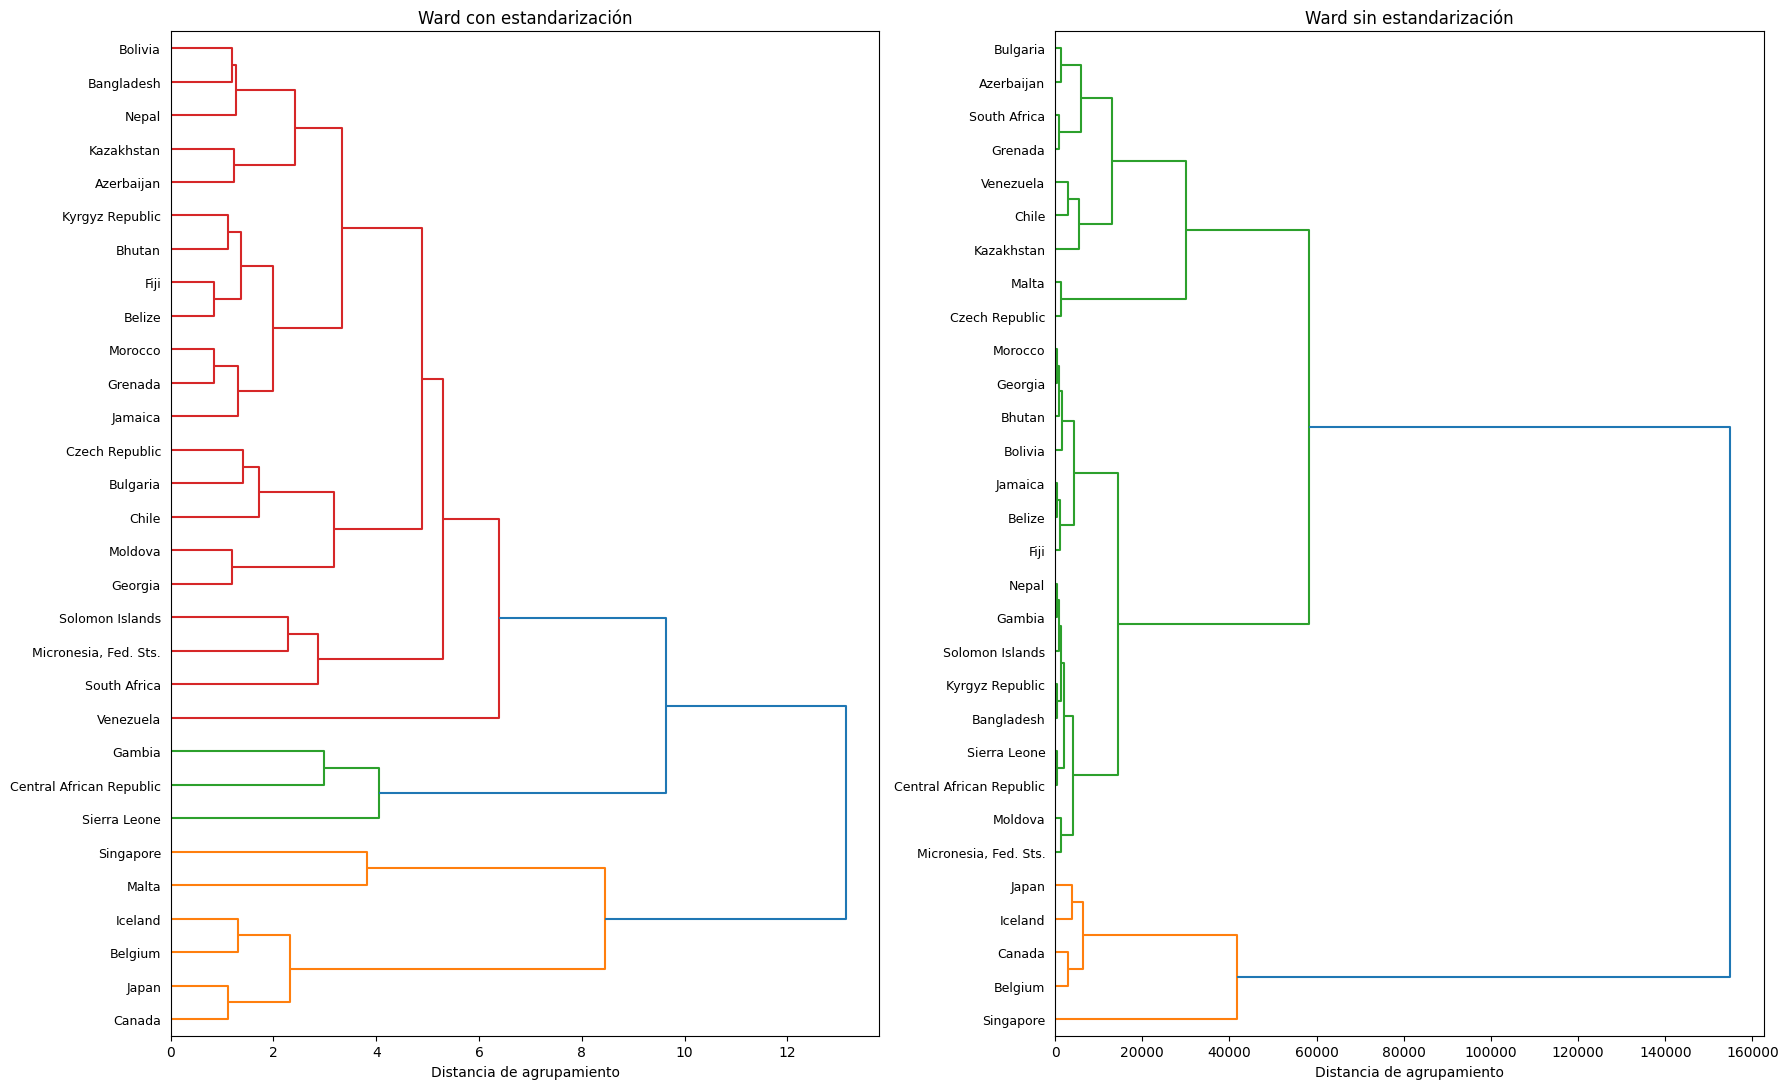

In [23]:

# Jerarquía con datos estandarizados
Z_escalado = linkage(
    X_paises_escalado,
    method="ward",
    metric="euclidean"
)

# Jerarquía con datos originales
Z_original = linkage(
    X_paises_original,
    method="ward",
    metric="euclidean"
)

# Comparar dendrogramas
fig, axes = plt.subplots(1, 2, figsize=(18, 11))

dendrogram(
    Z_escalado,
    labels=nombres_paises,
    orientation="right",
    leaf_font_size=9,
    ax=axes[0]
)

axes[0].set_title("Ward con estandarización")
axes[0].set_xlabel("Distancia de agrupamiento")

dendrogram(
    Z_original,
    labels=nombres_paises,
    orientation="right",
    leaf_font_size=9,
    ax=axes[1]
)

axes[1].set_title("Ward sin estandarización")
axes[1].set_xlabel("Distancia de agrupamiento")

plt.tight_layout()
plt.show()


**Interpretación preliminar**

**Comparación de métodos de enlace**

Para construir los dendrogramas utilicé cuatro métodos de enlace: single, complete, average y ward.

Cada método utiliza un criterio diferente para unir los países, por lo que las agrupaciones pueden cambiar dependiendo del enlace seleccionado.

También comparé Ward con datos originales y estandarizados para observar cómo influye la escala en los resultados.

Mi objetivo es identificar qué método permite obtener grupos más interpretables y analizar con cuáles países presenta mayor similitud Chile.

**Interpretación de los cuatro métodos**

**Comparación de los dendrogramas**

Al comparar los cuatro dendrogramas observé que los países se agrupan de diferentes maneras según el método utilizado.

Con Single se forma una especie de cadena, donde varios países se van incorporando a grupos existentes. Complete presenta separaciones más marcadas, mientras que Average muestra una estructura intermedia.

En Ward se pueden distinguir ramas más definidas, por lo que considero que es una buena opción para continuar el análisis.

También observé que Chile se une inicialmente con República Checa y Bulgaria en el dendrograma de Ward. Esto me llamó la atención porque esperaba encontrarlo cerca de otros países latinoamericanos.

Al comparar Ward con y sin estandarización, las agrupaciones cambiaron bastante. Sin estandarizar, las variables económicas con valores más grandes parecen tener mayor influencia en las distancias, por lo que considero más adecuado trabajar con los datos estandarizados.

**Evaluar cortes de 2, 3, 4 y 5 grupos**

In [24]:

from sklearn.metrics import silhouette_score

# Evaluar diferentes cortes con Ward
resultados_cortes = []

for k in range(2, 6):

    etiquetas = fcluster(
        Z_escalado,
        t=k,
        criterion="maxclust"
    )

    cantidad_grupos = len(np.unique(etiquetas))

    silueta = silhouette_score(
        X_paises_escalado,
        etiquetas
    )

    resultados_cortes.append({
        "Grupos solicitados": k,
        "Grupos obtenidos": cantidad_grupos,
        "Silueta": silueta
    })

df_cortes = pd.DataFrame(resultados_cortes)

display(df_cortes.round(4))


,Grupos solicitados,Grupos obtenidos,Silueta
0,2,2,0.3864
1,3,3,0.3702
2,4,4,0.3796
3,5,5,0.3825


**Graficar los resultados de silueta**

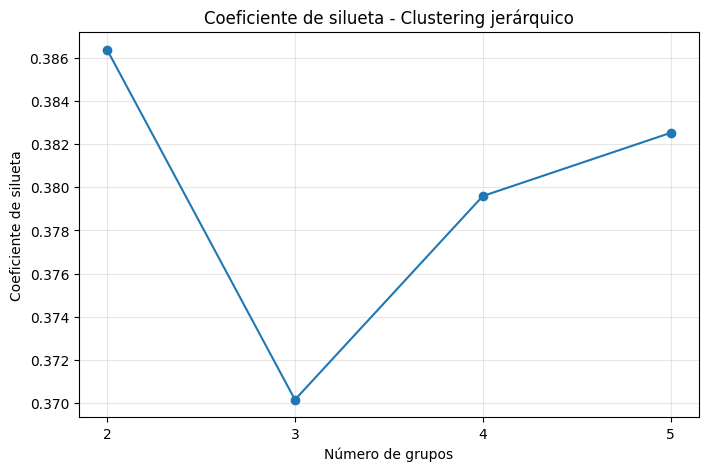

In [25]:

plt.figure(figsize=(8, 5))

plt.plot(
    df_cortes["Grupos solicitados"],
    df_cortes["Silueta"],
    marker="o"
)

plt.title("Coeficiente de silueta - Clustering jerárquico")
plt.xlabel("Número de grupos")
plt.ylabel("Coeficiente de silueta")
plt.xticks(range(2, 6))
plt.grid(alpha=0.3)

plt.show()


**Revisar las alturas de las fusiones**

In [26]:

# Obtener alturas de las fusiones
alturas = Z_escalado[:, 2]

# Calcular diferencias entre alturas consecutivas
saltos = np.diff(alturas)

# Mostrar los últimos saltos
df_alturas = pd.DataFrame({
    "Fusion": range(1, len(alturas) + 1),
    "Altura": alturas
})

print("Últimas fusiones:")
display(df_alturas.tail(10).round(4))

print("\nSaltos entre las últimas fusiones:")
display(
    pd.DataFrame({
        "Fusion posterior": range(2, len(alturas) + 1),
        "Salto": saltos
    }).tail(10).round(4)
)


Últimas fusiones:


,Fusion,Altura
19,20,3.1829
20,21,3.3296
21,22,3.8280
22,23,4.0569
23,24,4.9003
24,25,5.3024
25,26,6.3897
26,27,8.4553
27,28,9.6442
28,29,13.1379



Saltos entre las últimas fusiones:


,Fusion posterior,Salto
18,20,0.2035
19,21,0.1467
20,22,0.4984
21,23,0.2289
22,24,0.8434
23,25,0.4021
24,26,1.0873
25,27,2.0656
26,28,1.1888
27,29,3.4938


**Mostrar el dendrograma con una línea de corte**

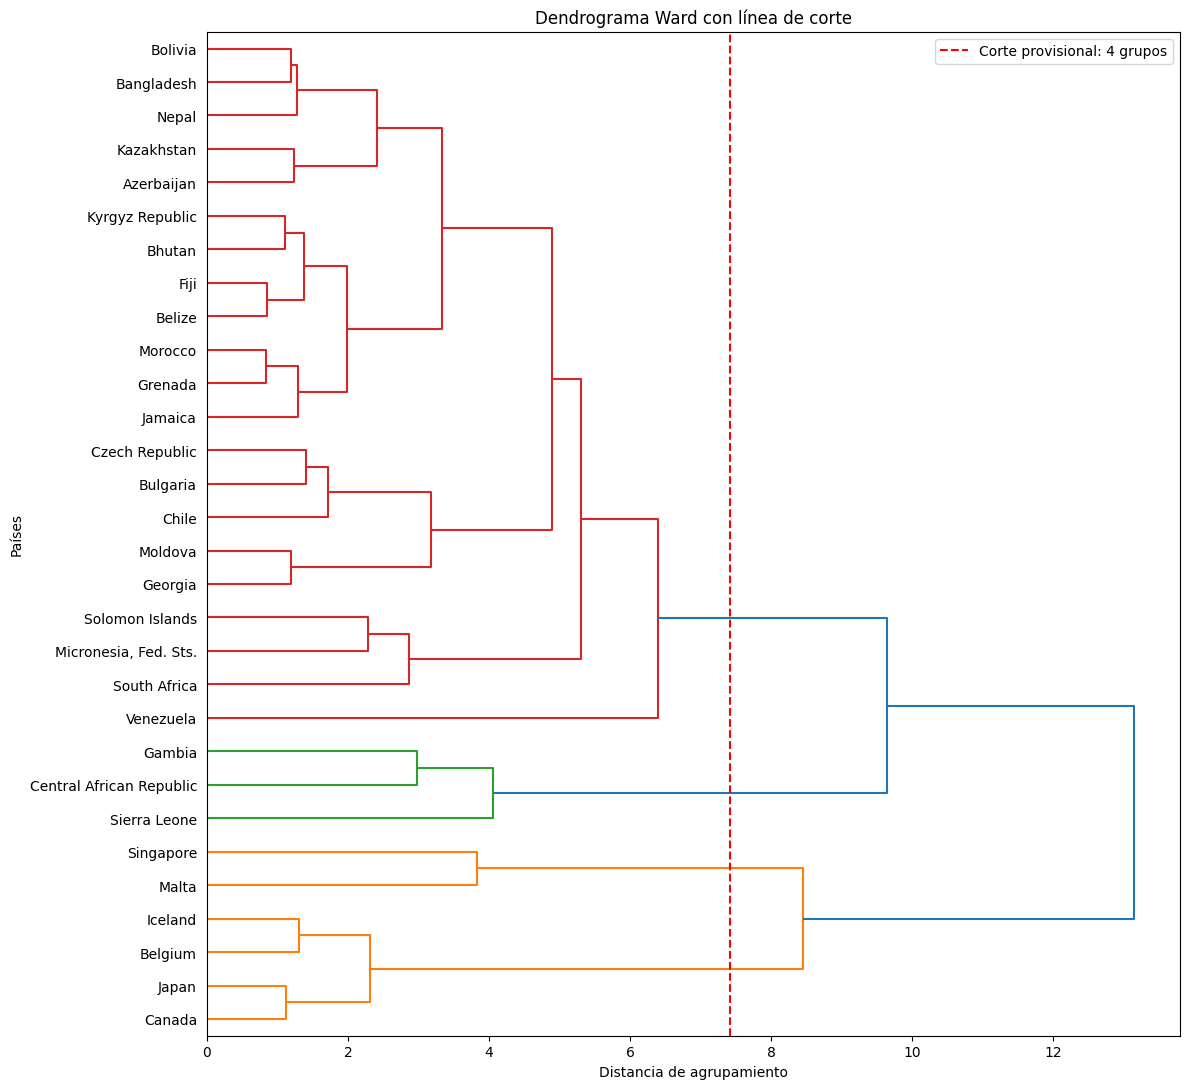

In [27]:

# Corte provisional
k_provisional = 4

# Altura de corte para obtener k grupos
n = len(nombres_paises)

altura_corte = (
    Z_escalado[n - k_provisional - 1, 2] +
    Z_escalado[n - k_provisional, 2]
) / 2

# Dibujar dendrograma
plt.figure(figsize=(12, 11))

dendrogram(
    Z_escalado,
    labels=nombres_paises,
    orientation="right",
    leaf_font_size=10
)

# Línea vertical porque el dendrograma es horizontal
plt.axvline(
    x=altura_corte,
    color="red",
    linestyle="--",
    label=f"Corte provisional: {k_provisional} grupos"
)

plt.title("Dendrograma Ward con línea de corte")
plt.xlabel("Distancia de agrupamiento")
plt.ylabel("Países")
plt.legend()
plt.tight_layout()
plt.show()


**Elegir el número de grupos**



Después de comparar los cortes de 2, 3, 4 y 5 grupos, decidí utilizar 4 grupos para el clustering jerárquico.

El valor más alto de silueta fue 0.3864 con 2 grupos, pero con 4 grupos se obtuvo un valor de 0.3796, que también es cercano.

Además, en el dendrograma se observa un salto importante entre las alturas 6.3897 y 8.4553, lo que permite justificar el corte en 4 grupos.

Elegí esta cantidad porque permite analizar los países con mayor detalle, sin generar demasiados grupos pequeños. De todas formas, la elección depende de las variables y del método utilizado.

**Identificar los países de cada grupo**

In [28]:

# Número de grupos elegido
k_final = 4

# Obtener etiquetas de los grupos
etiquetas_jerarquico = fcluster(
    Z_escalado,
    t=k_final,
    criterion="maxclust"
)

# Crear DataFrame con los grupos
df_jerarquico = df_muestra.copy()

df_jerarquico["Cluster"] = etiquetas_jerarquico

# Mostrar países por grupo
for cluster in sorted(df_jerarquico["Cluster"].unique()):

    paises = df_jerarquico[
        df_jerarquico["Cluster"] == cluster
    ]["country"].tolist()

    print(f"\nCluster {cluster} ({len(paises)} países):")

    for pais in paises:
        print("-", pais)



Cluster 1 (4 países):
- Belgium
- Canada
- Iceland
- Japan

Cluster 2 (2 países):
- Malta
- Singapore

Cluster 3 (3 países):
- Central African Republic
- Gambia
- Sierra Leone

Cluster 4 (21 países):
- Azerbaijan
- Bangladesh
- Belize
- Bhutan
- Bolivia
- Bulgaria
- Chile
- Czech Republic
- Fiji
- Georgia
- Grenada
- Jamaica
- Kazakhstan
- Kyrgyz Republic
- Micronesia, Fed. Sts.
- Moldova
- Morocco
- Nepal
- Solomon Islands
- South Africa
- Venezuela


**Identificar el grupo de Chile**

In [29]:

# Identificar el cluster de Chile
cluster_chile = df_jerarquico.loc[
    df_jerarquico["country"] == "Chile",
    "Cluster"
].iloc[0]

print("Chile pertenece al cluster:", cluster_chile)

# Mostrar los países del mismo grupo
paises_chile = df_jerarquico[
    df_jerarquico["Cluster"] == cluster_chile
]

print("\nPaíses agrupados con Chile:")

display(
    paises_chile[["country", "Cluster"]]
)


Chile pertenece al cluster: 4

Países agrupados con Chile:


,country,Cluster
0,Azerbaijan,4
1,Bangladesh,4
3,Belize,4
4,Bhutan,4
5,Bolivia,4
6,Bulgaria,4
9,Chile,4
10,Czech Republic,4
11,Fiji,4
13,Georgia,4


**Calcular los perfiles de cada grupo**

In [30]:

# Calcular promedios por cluster
perfiles_paises = df_jerarquico.groupby(
    "Cluster"
).agg({
    "child_mort": "mean",
    "exports": "mean",
    "health": "mean",
    "imports": "mean",
    "income": "mean",
    "inflation": "mean",
    "life_expec": "mean",
    "total_fer": "mean",
    "gdpp": "mean"
})

# Cantidad de países por cluster
cantidad_paises = df_jerarquico.groupby(
    "Cluster"
).size()

perfiles_paises.insert(
    0,
    "Cantidad_paises",
    cantidad_paises
)

print("Perfiles de los grupos:")
display(perfiles_paises.round(2))


Perfiles de los grupos:


,Cantidad_paises,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
Cluster,,,,,,,,,,
1,4,3.98,43.48,10.22,40.65,39100.0,2.08,81.53,1.77,44550.0
2,2,4.80,176.50,6.30,164.00,50200.0,1.89,81.50,1.25,33850.0
3,3,129.77,17.47,7.59,34.57,1256.0,7.84,56.00,5.37,469.0
4,21,27.65,39.08,6.77,49.73,9680.0,8.96,70.21,2.45,5391.9


**Comparar clustering jerárquico con K-means**

In [31]:

# Aplicar K-means con 4 grupos
modelo_kmeans_paises = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

etiquetas_kmeans = modelo_kmeans_paises.fit_predict(
    X_paises_escalado
)

# Comparar los dos métodos
comparacion_metodos = pd.crosstab(
    pd.Series(
        etiquetas_jerarquico,
        name="Jerárquico"
    ),
    pd.Series(
        etiquetas_kmeans,
        name="K-means"
    )
)

print("Tabla de comparación:")
display(comparacion_metodos)

# Calcular ARI
ari_metodos = adjusted_rand_score(
    etiquetas_jerarquico,
    etiquetas_kmeans
)

print(
    "\nÍndice de Rand ajustado:",
    round(ari_metodos, 4)
)


Tabla de comparación:


K-means,0,1,2,3
Jerárquico,,,,
1,0,0,4,0
2,0,2,0,0
3,0,0,0,3
4,20,0,1,0



Índice de Rand ajustado: 0.8897


**Comparar los grupos de Chile en ambos métodos**

In [32]:

# Agregar etiquetas de K-means
df_jerarquico["Cluster_Kmeans"] = etiquetas_kmeans

# Obtener el grupo de Chile en K-means
cluster_chile_kmeans = df_jerarquico.loc[
    df_jerarquico["country"] == "Chile",
    "Cluster_Kmeans"
].iloc[0]

print("Grupo de Chile en Ward:", cluster_chile)
print("Grupo de Chile en K-means:", cluster_chile_kmeans)

print("\nPaíses agrupados con Chile mediante K-means:")

display(
    df_jerarquico.loc[
        df_jerarquico["Cluster_Kmeans"] == cluster_chile_kmeans,
        ["country", "Cluster_Kmeans"]
    ]
)


Grupo de Chile en Ward: 4
Grupo de Chile en K-means: 0

Países agrupados con Chile mediante K-means:


,country,Cluster_Kmeans
0,Azerbaijan,0
1,Bangladesh,0
3,Belize,0
4,Bhutan,0
5,Bolivia,0
6,Bulgaria,0
9,Chile,0
11,Fiji,0
13,Georgia,0
14,Grenada,0


**Interpretación de los grupos obtenidos**

El clustering jerárquico con Ward permitió identificar cuatro grupos de países.

El cluster 1 contiene 4 países con ingresos altos, esperanza de vida elevada y baja mortalidad infantil. El cluster 2 contiene 2 países que destacan por sus valores altos de exportaciones e importaciones.

El cluster 3 agrupa a 3 países con ingresos bajos, mayor mortalidad infantil y menor esperanza de vida.

Finalmente, el cluster 4 contiene 21 países con indicadores más variados y niveles económicos intermedios en comparación con los otros grupos.

Chile pertenece al cluster 4, junto con países como Bolivia, Bulgaria, Georgia y Venezuela. Esto significa que presentan similitudes considerando las variables utilizadas, aunque no necesariamente son iguales en todos sus indicadores.

**Comparación entre clustering jerárquico y K-means**

Al comparar ambos métodos obtuve un índice de Rand ajustado de 0.8897, lo que indica que existe un acuerdo alto entre las agrupaciones.

La mayoría de los países quedaron agrupados de la misma manera. La principal diferencia fue República Checa, que en Ward aparece junto con Chile, pero en K-means pertenece a otro grupo.

Esto ocurre porque Ward busca minimizar el aumento de la variabilidad interna al unir grupos, mientras que K-means busca minimizar las distancias cuadráticas de las observaciones a sus centroides.

Considero que ambos métodos entregaron resultados similares, aunque Ward permite observar mejor cómo se van formando los grupos mediante el dendrograma.

**Conclusión final ejercicio 2**

En este ejercicio utilicé clustering jerárquico para analizar las similitudes entre 30 países, incluyendo a Chile.

Elegí Ward con 4 grupos porque permitió obtener agrupaciones interpretables y una silueta de 0.3796.

Chile quedó agrupado con países como Bolivia, Bulgaria, Georgia y Venezuela, entre otros.

Al comparar Ward con K-means obtuve un ARI de 0.8897, lo que demuestra que ambos métodos encontraron grupos bastante similares.

La principal diferencia fue República Checa, que cambió de grupo al utilizar K-means.

Presentaría los resultados de Ward a la organización porque el dendrograma permite visualizar las relaciones entre los países y analizar diferentes niveles de agrupación.

Como limitación, los resultados dependen de la muestra, las variables y la estandarización, por lo que no se puede afirmar que los países sean iguales ni establecer un ranking de desarrollo a partir de estos grupos.